# 05 Evaluation and Error Analysis

## Goal

Accuracy alone does not tell the whole story. We will evaluate the trained models on the held-out CIFAR-10 test set and inspect individual mistakes.

Run Notebook 03 first. Notebook 04 is optional; this notebook evaluates whichever saved models are available.


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import cifar10
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

(_, _), (x_test_raw, y_test_raw) = cifar10.load_data()
y_test = y_test_raw.squeeze()
x_test = x_test_raw.astype("float32") / 255.0

print("Test images:", x_test.shape)


2026-11-01 18:06:46.592090: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-01 18:06:46.864413: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793556407.042263    5432 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793556407.081405    5432 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793556409.160480    5432 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

Test images: (10000, 32, 32, 3)


## 1. Load and evaluate the small CNN

We use the untouched test set only now, after training choices have been made.


In [2]:
cnn_path = "../artifacts/cifar10_cnn.keras"
cnn = keras.models.load_model(cnn_path)

cnn_loss, cnn_acc = cnn.evaluate(x_test, y_test, verbose=0)
cnn_probs = cnn.predict(x_test, batch_size=128, verbose=0)
cnn_pred = np.argmax(cnn_probs, axis=1)

print(f"Small CNN test loss: {cnn_loss:.4f}")
print(f"Small CNN test accuracy: {cnn_acc:.4f}")
print(classification_report(y_test, cnn_pred, target_names=CLASS_NAMES, zero_division=0))


I0000 00:00:1793556417.151648    5432 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3617 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
I0000 00:00:1793556425.625891    5574 service.cc:152] XLA service 0x7d9bb4005850 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793556425.626026    5574 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6
2026-11-01 18:07:05.660499: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793556425.739373    5574 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1793556429.062434    5574 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2026-11-01 1

Small CNN test loss: 0.8472
Small CNN test accuracy: 0.7031
              precision    recall  f1-score   support

    airplane       0.67      0.83      0.74      1000
  automobile       0.84      0.82      0.83      1000
        bird       0.64      0.49      0.55      1000
         cat       0.55      0.48      0.51      1000
        deer       0.57      0.73      0.64      1000
         dog       0.73      0.44      0.55      1000
        frog       0.69      0.82      0.75      1000
       horse       0.72      0.80      0.75      1000
        ship       0.91      0.76      0.83      1000
       truck       0.78      0.85      0.81      1000

    accuracy                           0.70     10000
   macro avg       0.71      0.70      0.70     10000
weighted avg       0.71      0.70      0.70     10000



## 2. Confusion matrix

Rows are true classes and columns are predicted classes. Off-diagonal values show mistakes. Look for pairs of classes that the model confuses repeatedly.


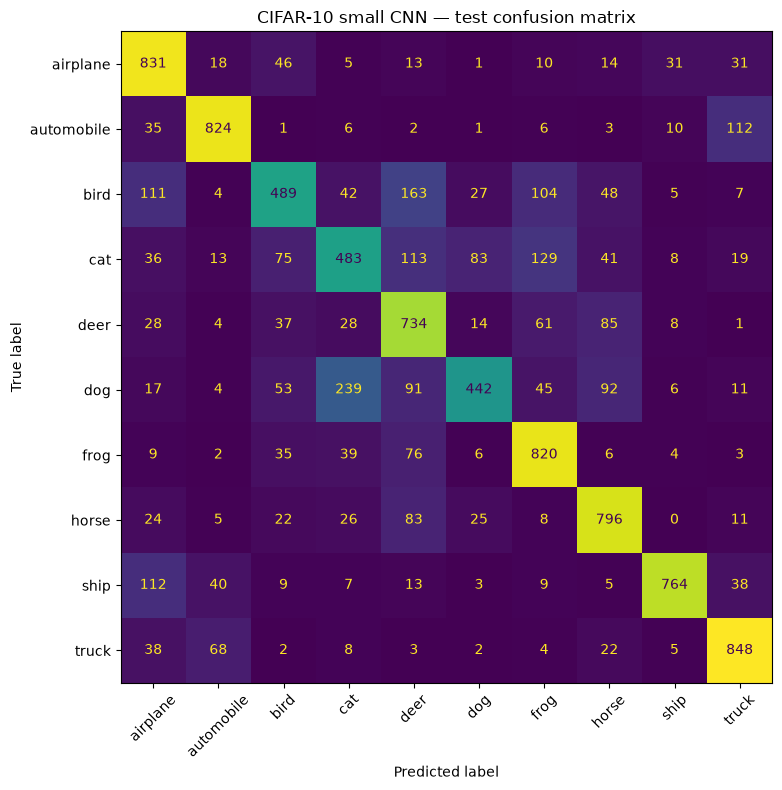

In [3]:
cm = confusion_matrix(y_test, cnn_pred)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, xticks_rotation=45, colorbar=False
)
plt.title("CIFAR-10 small CNN — test confusion matrix")
plt.tight_layout()
plt.show()


## 3. Inspect misclassified images

The following cell displays a few examples where the predicted class differs from the true class. Ask whether the image is ambiguous, low-resolution, or visually similar to another class.


Misclassified examples: 2969 out of 10000


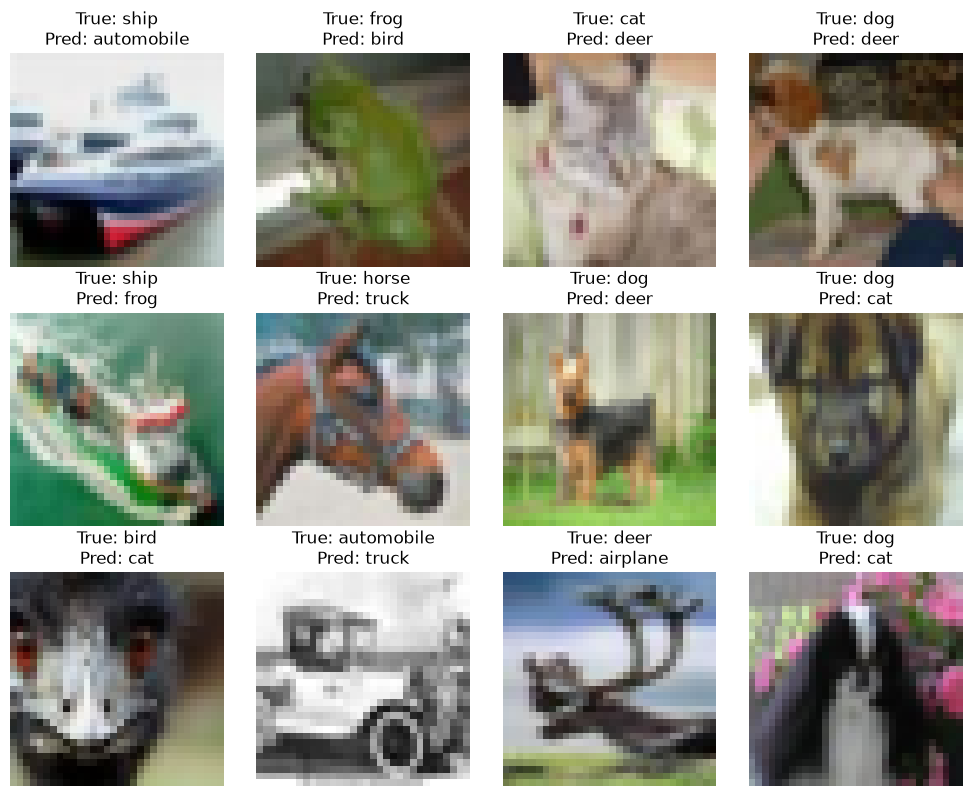

In [4]:
wrong = np.flatnonzero(cnn_pred != y_test)
print("Misclassified examples:", len(wrong), "out of", len(y_test))

n_show = min(12, len(wrong))
fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax, idx in zip(axes.flat, wrong[:n_show]):
    ax.imshow(x_test_raw[idx])
    ax.set_title(
        f"True: {CLASS_NAMES[y_test[idx]]}\nPred: {CLASS_NAMES[cnn_pred[idx]]}"
    )
    ax.axis("off")

for ax in axes.flat[n_show:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 4. Optional: compare transfer learning

If Notebook 04 ran successfully and saved the MobileNetV2 model, evaluate it using the same test set. Do not compare results from different test splits.


In [5]:
transfer_path = "../artifacts/cifar10_mobilenetv2.keras"

if os.path.exists(transfer_path):
    transfer_model = keras.models.load_model(transfer_path)

    def prepare_for_mobilenet(image, label):
        image = tf.cast(image, tf.float32)
        image = tf.image.resize(image, (96, 96))
        image = keras.applications.mobilenet_v2.preprocess_input(image)
        return image, label

    transfer_test_ds = (
        tf.data.Dataset.from_tensor_slices((x_test_raw, y_test))
        .map(prepare_for_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(64).prefetch(tf.data.AUTOTUNE)
    )

    transfer_loss, transfer_acc = transfer_model.evaluate(transfer_test_ds, verbose=0)
    print(f"MobileNetV2 test loss: {transfer_loss:.4f}")
    print(f"MobileNetV2 test accuracy: {transfer_acc:.4f}")
else:
    print("Transfer model not found. Run Notebook 04 to enable this comparison.")


2026-11-01 18:07:18.210562: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1156', 4 bytes spill stores, 4 bytes spill loads

2026-11-01 18:07:18.337883: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1156', 60 bytes spill stores, 60 bytes spill loads

2026-11-01 18:07:18.485946: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1156', 948 bytes spill stores, 948 bytes spill loads

2026-11-01 18:07:18.533839: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1156', 1180 bytes spill stores, 1244 bytes spill loads

2026-11-01 18:07:23.116906: E extern

MobileNetV2 test loss: 0.4093
MobileNetV2 test accuracy: 0.8680


## Reflection

1. Why can accuracy hide poor performance on one class?
2. What does a confusion matrix reveal?
3. Are all misclassifications equally concerning?
4. What evidence would you inspect before claiming one model is better?
5. How would you repeat this evaluation on EuroSAT without changing the meaning of the labels?
